| Inicio | Anterior | Siguiente |
| --- | --- | --- |
| [🏠](../README.md) | [⏪](../15_SCIENTIFIC_MACHINE_LEARNING/15_1_Physics_Informed_Neural_Networks.ipynb) | [⏩](../15_SCIENTIFIC_MACHINE_LEARNING/15_3_Neural_Operators.ipynb) |

# 15.2 PINNs: sílabus práctico de ODE, PDE e identificación

Este notebook amplía la introducción de 15.1 con una PDE real y un pequeño problema inverso. El objetivo es comprender **qué se modela, qué se diferencia y cómo se comprueba** una PINN. El recorrido termina con un proyecto y criterios de evaluación que puedes reutilizar al estudiar artículos.

**Prerrequisitos:** 4.2 derivadas parciales, 5.1 ODE, 8.1 PDE, 10.2 gradiente y 12.1 redes. **Librerías:** NumPy, Matplotlib y PyTorch. Los entrenamientos son pequeños y usan CPU; según tu equipo pueden tardar varios segundos o minutos. Ejecuta las celdas en orden.

## 1. Un sílabus con resultados comprobables

| Etapa | Pregunta que debes responder | Evidencia que producirás |
|---|---|---|
| Formulación | ¿Qué ecuación y condiciones definen el problema? | Dominio, unidades y solución de referencia |
| Diferenciación | ¿Cómo obtengo $u_t$ y $u_{xx}$? | Comparación autograd/derivada exacta |
| Restricciones | ¿Cómo impongo condiciones iniciales y de borde? | Evaluación explícita de sus errores |
| Colocación | ¿Dónde evalúo el residuo? | Gráfico del muestreo interior |
| Entrenamiento | ¿Qué términos optimizo? | Historial desglosado de pérdidas |
| Validación | ¿Qué ocurre en puntos nuevos? | Error de solución y residuo independiente |
| Inversión | ¿Qué parámetro identifica la observación? | Estimación y análisis de sensibilidad |
| Investigación | ¿Qué cambia con semillas y escalas? | Tabla de experimentos y limitaciones |

Puedes estudiar una etapa por sesión. Los experimentos de este notebook constituyen una base verificable; una investigación completa requiere probar problemas y resoluciones adicionales.

## 2. Ecuación del calor en una barra

Sea $u(x,t)$ la temperatura relativa al ambiente en una barra de longitud normalizada uno. Su evolución es

$$u_t=\alpha u_{xx},\quad 0<x<1,\quad0<t\leq1,$$
$$u(0,t)=u(1,t)=0,\qquad u(x,0)=\sin(\pi x).$$

Los extremos se mantienen a temperatura ambiente. La difusión redistribuye calor y la temperatura disminuye. El coeficiente $\alpha>0$ mide difusividad; en variables dimensionales tiene unidades de longitud al cuadrado por tiempo.

Por separación de variables, $X''=-\pi^2 X$ y $A'=-\alpha\pi^2A$. Por tanto,

$$\boxed{u(x,t)=\sin(\pi x)e^{-\alpha\pi^2t}.}$$

Usaremos $\alpha=0.1$. A tiempo uno, la amplitud vale $e^{-0.1\pi^2}\approx0.373$. La PINN no recibe esta expresión como etiqueta interior: la usamos para verificarla.

Para una barra dimensional de longitud $L$ y tiempo de referencia $t_c$, $\xi=x/L$ y $\tau=t/t_c$ convierten el coeficiente en $\alpha t_c/L^2$. No es correcto normalizar coordenadas y mantener arbitrariamente el coeficiente dimensional.

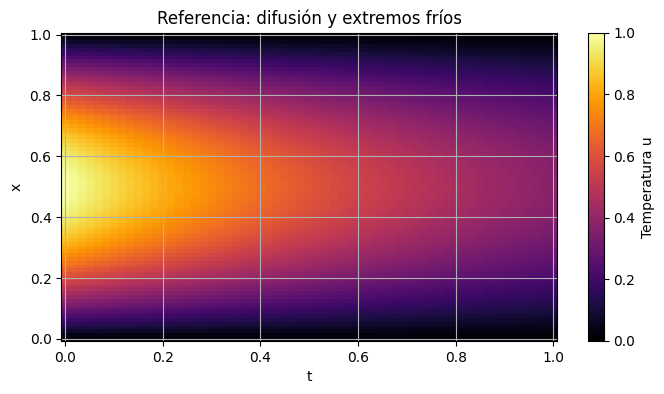

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn

torch.manual_seed(152)
torch.set_num_threads(1)
torch.set_default_dtype(torch.float64)
rng = np.random.default_rng(152)
alpha = 0.1
def referencia(x, t):
    return np.sin(np.pi*x) * np.exp(-alpha*np.pi**2*t)
x_plot = np.linspace(0, 1, 81)
t_plot = np.linspace(0, 1, 61)
X, TT = np.meshgrid(x_plot, t_plot, indexing='ij')
plt.figure(figsize=(8, 4))
plt.pcolormesh(TT, X, referencia(X, TT), shading='auto', cmap='inferno')
plt.colorbar(label='Temperatura u'); plt.xlabel('t'); plt.ylabel('x')
plt.title('Referencia: difusión y extremos fríos'); plt.show()

## 3. Condiciones blandas y condiciones exactas

Con una red libre, una formulación usual minimiza

$$\mathcal L=\lambda_r\operatorname{MSE}(u_t-\alpha u_{xx})+
\lambda_b\operatorname{MSE}(u|_{\partial\Omega})+
\lambda_i\operatorname{MSE}(u(x,0)-\sin\pi x).$$

Los términos de borde e inicial son condiciones **blandas**: pueden quedar pequeños errores. Para este dominio simple podemos construir

$$\boxed{u_\theta(x,t)=\sin(\pi x)+t\,x(1-x)N_\theta(x,t).}$$

Si $t=0$, desaparece la corrección y obtenemos la condición inicial. Si $x=0$ o $1$, desaparece la corrección y el seno también vale cero. Así se satisfacen las tres condiciones hasta precisión de redondeo para cualquier $\theta$.

La arquitectura incorpora las condiciones, **no la solución exacta**: $N_\theta$ aún debe aprender el decaimiento temporal. Solo entrenaremos el residuo interior. Este truco depende de la geometría y puede introducir factores pequeños cerca de los bordes; no es automáticamente adecuado para todos los dominios o condiciones de Neumann.

In [2]:
class CalorPINN(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(2, 32), nn.Tanh(),
                                 nn.Linear(32, 32), nn.Tanh(), nn.Linear(32, 1))
    def forward(self, xt):
        x, t = xt[:, :1], xt[:, 1:]
        correccion = self.net(2*xt-1)
        return torch.sin(torch.pi*x) + t*x*(1-x)*correccion

modelo = CalorPINN()
def derivadas_calor(red, xt):
    u = red(xt)
    grad = torch.autograd.grad(u, xt, torch.ones_like(u), create_graph=True)[0]
    ux, ut = grad[:, :1], grad[:, 1:]
    grad2 = torch.autograd.grad(ux, xt, torch.ones_like(ux), create_graph=True)[0]
    uxx = grad2[:, :1]
    return u, ut, uxx

demo = torch.tensor([[0.2, 0.3], [0.7, 0.8]], requires_grad=True)
class ExactaTorch(nn.Module):
    def forward(self, xt):
        return torch.sin(torch.pi*xt[:, :1])*torch.exp(-alpha*torch.pi**2*xt[:, 1:])
ue, ute, uxxe = derivadas_calor(ExactaTorch(), demo)
print('Residuo de la referencia:', (ute-alpha*uxxe).abs().max().item())

Residuo de la referencia: 5.551115123125783e-17


## 4. Derivadas parciales y regla de la cadena

La primera llamada a autograd entrega dos columnas: $u_x$ y $u_t$. Al derivar la columna $u_x$ obtenemos otra matriz: su primera columna es $u_{xx}$ y la segunda es $u_{xt}$. Seleccionar la columna incorrecta modifica la ecuación.

La segunda derivada necesita un grafo diferenciable de la primera, y el entrenamiento necesita diferenciar ese resultado respecto a los pesos. Evita `detach()` y conversiones a NumPy dentro del cálculo del residuo. Ambas rompen la cadena de derivación. Para gráficos sí podemos convertir después de terminar el cálculo.

Los modelos están en precisión de 64 bits para reducir errores de redondeo al calcular derivadas. Esto consume más memoria que 32 bits. Para otros problemas conviene comprobar ambas precisiones antes de fijar una política.

## 5. Muestrear el interior del espacio y tiempo

Los puntos de colocación aproximan una integral del residuo cuadrático. Un muestreo uniforme cubre el dominio sin información sobre dónde fallará la red. Si existe una capa de borde o un frente, puede necesitarse mayor resolución local.

Usaremos 192 puntos aleatorios fijos. Así la pérdida de cada iteración es comparable. Remuestrear puede reducir sobreajuste al conjunto de colocación, pero cambia el objetivo empírico de una iteración a otra. El conjunto de validación será una malla independiente y más densa.

El residuo tampoco representa por sí solo una norma de error de solución. Una PDE mal planteada o una condición incorrecta puede producir una aproximación poco útil aunque parte de los residuos disminuya.

MSE residuo, inicio y final: 0.5166281707124282 3.694697500812386e-06


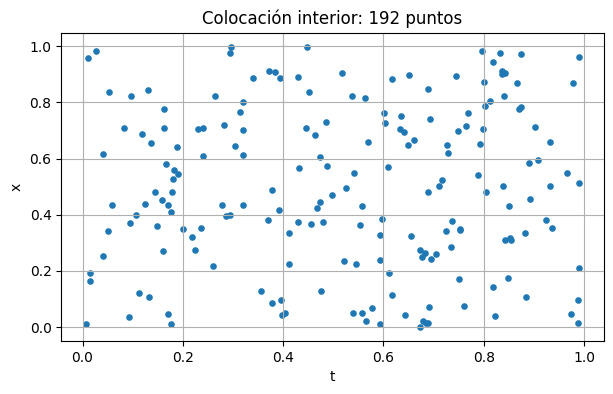

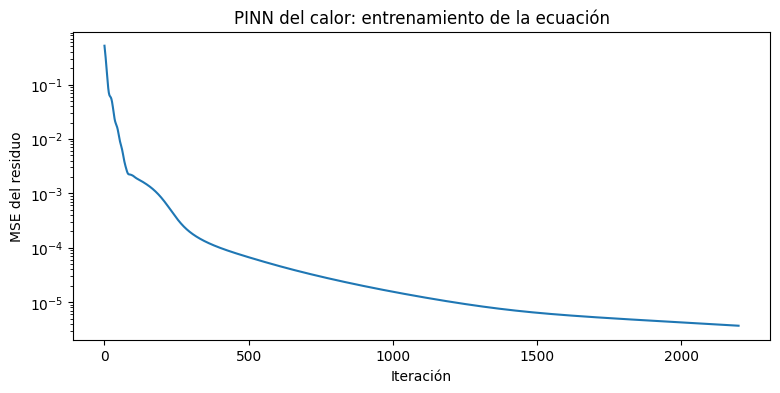

In [3]:
colocacion = torch.tensor(rng.uniform(0, 1, (192, 2)), requires_grad=True)
plt.figure(figsize=(7, 4))
plt.scatter(colocacion.detach().numpy()[:, 1], colocacion.detach().numpy()[:, 0], s=14)
plt.xlabel('t'); plt.ylabel('x'); plt.title('Colocación interior: 192 puntos')
plt.show()
opt = torch.optim.Adam(modelo.parameters(), lr=0.003)
historial = []
for paso in range(2200):
    opt.zero_grad(set_to_none=True)
    colocacion.grad = None
    _, ut, uxx = derivadas_calor(modelo, colocacion)
    loss = ((ut-alpha*uxx)**2).mean()
    loss.backward()
    opt.step()
    historial.append(loss.item())
print('MSE residuo, inicio y final:', historial[0], historial[-1])
plt.semilogy(historial)
plt.xlabel('Iteración'); plt.ylabel('MSE del residuo')
plt.title('PINN del calor: entrenamiento de la ecuación'); plt.grid(); plt.show()

## 6. Qué demuestra y qué no demuestra el entrenamiento

La arquitectura ya satisface las condiciones, por lo que la pérdida grafica únicamente la ecuación interior. Una disminución indica progreso en los puntos muestreados. Para declarar una solución útil necesitamos verificar temperatura, residuo nuevo y condiciones por separado.

Adam es una elección práctica, no una condición definitoria de una PINN. Un segundo ajuste con L-BFGS puede ayudar en algunos problemas suaves. Este notebook mantiene un solo optimizador para que el cálculo sea fácil de reproducir. Si cambia la semilla o el número de puntos, el número de iteraciones necesario puede variar.

Error relativo L2 discreto: 0.0004333383585959563
Error máximo: 0.0005441780172666943


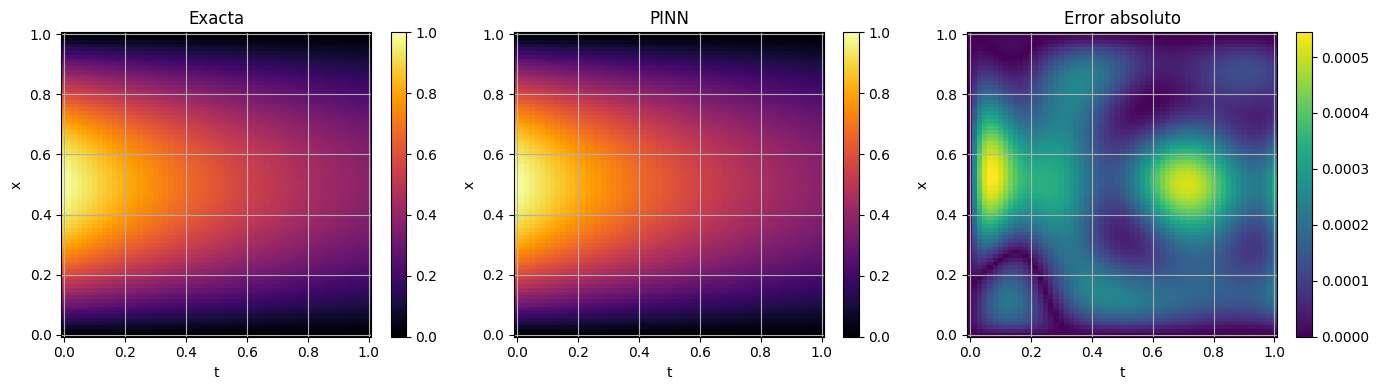

In [4]:
xt_test = torch.tensor(np.column_stack([X.ravel(), TT.ravel()]))
with torch.no_grad():
    aprendido = modelo(xt_test).numpy().reshape(X.shape)
verdad = referencia(X, TT)
error = aprendido-verdad
relativo = np.linalg.norm(error)/np.linalg.norm(verdad)
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, datos, titulo, cmap in zip(axes, [verdad, aprendido, np.abs(error)],
        ['Exacta', 'PINN', 'Error absoluto'], ['inferno', 'inferno', 'viridis']):
    imagen = ax.pcolormesh(TT, X, datos, shading='auto', cmap=cmap)
    fig.colorbar(imagen, ax=ax)
    ax.set(xlabel='t', ylabel='x', title=titulo)
plt.tight_layout(); plt.show()
print('Error relativo L2 discreto:', relativo)
print('Error máximo:', np.abs(error).max())
assert np.isfinite(aprendido).all()
assert relativo < 0.05, 'Revisar entrenamiento: error superior al objetivo didáctico.'

## 7. Medir el error y examinar cortes

La norma reportada es una aproximación discreta no ponderada a $L^2$ en una malla uniforme. En una malla irregular necesitaríamos pesos de cuadratura. El error máximo detecta desviaciones locales que un promedio puede ocultar.

En los mapas de calor la escala del error difiere de la escala de temperatura. No compares colores entre barras diferentes como si indicaran la misma magnitud. Los cortes temporales siguientes facilitan ver condiciones y forma de la solución.

Error bordes: 1.2246467991473532e-16
Error inicial: 0.0
RMS residuo independiente: 0.002218682556980068


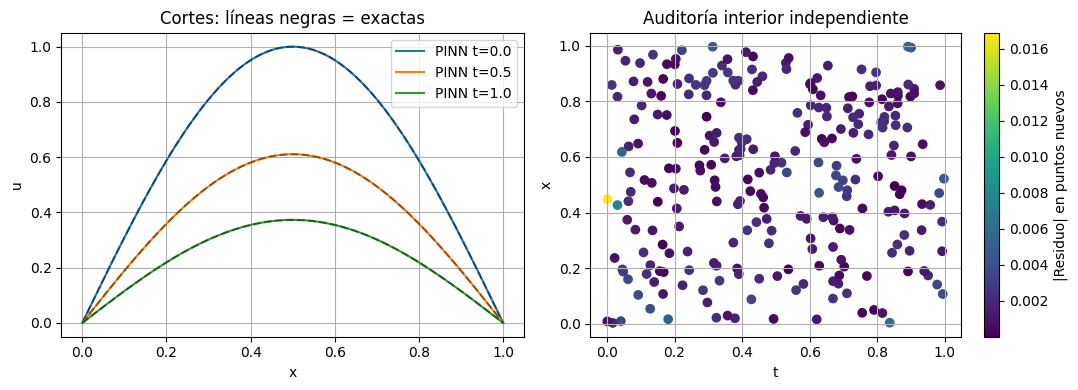

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for t_corte in [0.0, 0.5, 1.0]:
    pts = torch.tensor(np.column_stack([x_plot, np.full_like(x_plot, t_corte)]))
    with torch.no_grad(): u_corte = modelo(pts).numpy().ravel()
    axes[0].plot(x_plot, u_corte, label=f'PINN t={t_corte}')
    axes[0].plot(x_plot, referencia(x_plot, t_corte), 'k--', alpha=0.4)
audit = torch.tensor(rng.uniform(0, 1, (257, 2)), requires_grad=True)
_, ut_a, uxx_a = derivadas_calor(modelo, audit)
res_a = (ut_a-alpha*uxx_a).detach().numpy().ravel()
sc = axes[1].scatter(audit.detach().numpy()[:, 1], audit.detach().numpy()[:, 0],
                     c=np.abs(res_a), cmap='viridis')
fig.colorbar(sc, ax=axes[1], label='|Residuo| en puntos nuevos')
axes[0].set(xlabel='x', ylabel='u', title='Cortes: líneas negras = exactas')
axes[1].set(xlabel='t', ylabel='x', title='Auditoría interior independiente')
axes[0].legend(); plt.tight_layout(); plt.show()
with torch.no_grad():
    borde0 = modelo(torch.tensor(np.column_stack([np.zeros_like(t_plot), t_plot])))
    borde1 = modelo(torch.tensor(np.column_stack([np.ones_like(t_plot), t_plot])))
    inicial = modelo(torch.tensor(np.column_stack([x_plot, np.zeros_like(x_plot)]))).ravel()
print('Error bordes:', max(borde0.abs().max().item(), borde1.abs().max().item()))
print('Error inicial:', (inicial-torch.sin(torch.pi*torch.tensor(x_plot))).abs().max().item())
print('RMS residuo independiente:', np.sqrt(np.mean(res_a**2)))

## 8. La conservación se comprueba con los flujos

Definimos la cantidad térmica normalizada $H(t)=\int_0^1u(x,t)dx$. Integrar la PDE produce

$$\frac{dH}{dt}=\alpha[u_x(1,t)-u_x(0,t)].$$

La barra pierde calor por sus extremos; $H$ no es constante bajo estas condiciones. Para la referencia, $H(t)=2e^{-\alpha\pi^2t}/\pi$ y su derivada es negativa.

Esta identidad permite distinguir un error de modelo de un error de aproximación: pedir conservación de $H$ sería físicamente incorrecto aquí. En el ejercicio final puedes contrastar la integral de la PINN y los gradientes de borde mediante autograd.

## 9. Identificar un parámetro: un inverso controlado

Pasemos a una ODE de decaimiento con tasa desconocida. Aprenderemos $u_\theta(t)=1+tN_\theta(t)$ y $k_\eta=\operatorname{softplus}(\eta)$ a partir de ocho observaciones en $[0,2]$:

$$\mathcal L=\operatorname{MSE}(u_\theta-y)+
\operatorname{MSE}(u'_\theta+k_\eta u_\theta).$$

Ahora el residuo tiene dos incógnitas: la función y el parámetro. Sin datos, cada $k$ tiene una solución válida; la física sola no identifica la tasa. Las mediciones en tiempos distintos de cero distinguen esas soluciones. Utilizamos datos sin ruido para comprobar el mecanismo de inversión; una estimación bajo ruido necesita además un modelo estadístico y análisis de incertidumbre.

k inferido: 0.6996799178494214 | real: 0.7


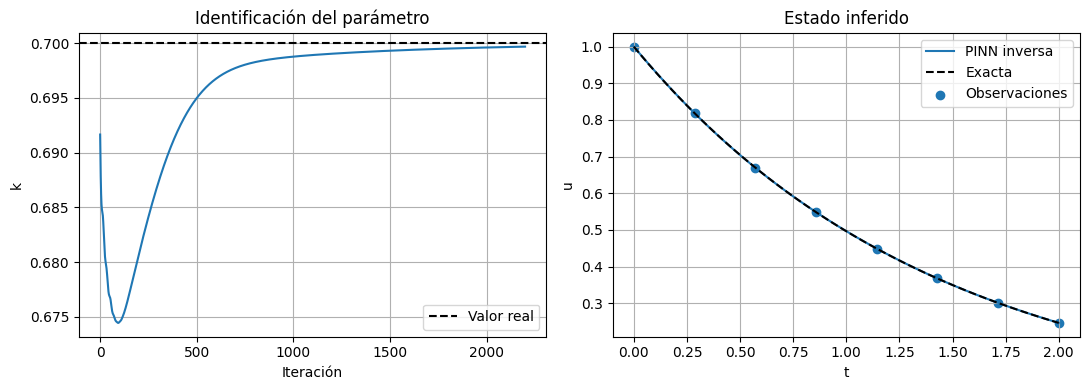

In [6]:
torch.manual_seed(153)
k_real = 0.7
t_obs = torch.linspace(0, 2, 8).reshape(-1, 1)
y_obs = torch.exp(-k_real*t_obs)
t_col = torch.linspace(0, 2, 64).reshape(-1, 1).requires_grad_(True)
red_inversa = nn.Sequential(nn.Linear(1, 24), nn.Tanh(), nn.Linear(24, 24),
                            nn.Tanh(), nn.Linear(24, 1))
eta = nn.Parameter(torch.tensor(0.0))
def estado_inverso(t):
    return 1 + t*red_inversa(t-1)
opt_inv = torch.optim.Adam(list(red_inversa.parameters())+[eta], lr=0.003)
hist_k = []
for _ in range(2200):
    opt_inv.zero_grad(set_to_none=True); t_col.grad = None
    u = estado_inverso(t_col)
    du = torch.autograd.grad(u, t_col, torch.ones_like(u), create_graph=True)[0]
    k_estimado = torch.nn.functional.softplus(eta)
    loss = ((estado_inverso(t_obs)-y_obs)**2).mean() + ((du+k_estimado*u)**2).mean()
    loss.backward(); opt_inv.step()
    hist_k.append(torch.nn.functional.softplus(eta).item())
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(hist_k); ax[0].axhline(k_real, color='k', linestyle='--', label='Valor real')
ax[0].set(xlabel='Iteración', ylabel='k', title='Identificación del parámetro'); ax[0].legend()
t_iv = torch.linspace(0, 2, 101).reshape(-1, 1)
with torch.no_grad(): p_iv = estado_inverso(t_iv).numpy().ravel()
ax[1].plot(t_iv.numpy().ravel(), p_iv, label='PINN inversa')
ax[1].plot(t_iv.numpy().ravel(), np.exp(-k_real*t_iv.numpy().ravel()), 'k--', label='Exacta')
ax[1].scatter(t_obs.numpy(), y_obs.numpy(), label='Observaciones')
ax[1].set(xlabel='t', ylabel='u', title='Estado inferido'); ax[1].legend()
plt.tight_layout(); plt.show()
print('k inferido:', hist_k[-1], '| real:', k_real)
assert abs(hist_k[-1]-k_real) < 0.08

## 10. Sensibilidad e identificabilidad

Para $u=e^{-kt}$,

$$\partial_k u=-te^{-kt}.$$

En $t=0$ la sensibilidad vale cero. Para ruido de varianza constante, tiempos cercanos a $t=1/k$ maximizan la magnitud de esta sensibilidad; tiempos demasiado tardíos tienen señales pequeñas. Con un modelo de ruido relativo, el diseño óptimo puede cambiar.

Recuperar $k$ en un experimento sin ruido no demuestra identificabilidad de una PDE con varios coeficientes. Dos parámetros pueden producir observaciones muy parecidas; también puede existir una compensación entre error de red y parámetro inferido. Examina perfiles de pérdida, repeticiones y bandas de incertidumbre antes de interpretar valores físicos.

## 11. Fallos de optimización que debes estudiar

Una PINN puede fallar por diferencias de escala entre pérdidas, gradientes mal equilibrados, sesgo hacia funciones suaves o baja cobertura del dominio. Frentes abruptos, ecuaciones rígidas y soluciones oscilatorias son más difíciles que la difusión suave de este notebook.

Las mejoras deben responder a una observación: adimensionalización si las escalas dominan; muestreo adaptativo si hay residuos localizados; arquitectura suave si se requieren derivadas; descomposición de dominio si una única red no representa regiones distintas. Ninguna técnica garantiza que una PINN supere a un solver clásico.

La independencia de una malla de discretización tradicional no implica ausencia de muestreo ni de error numérico: las PINNs usan colocación finita, precisión finita y optimización aproximada.

## 12. Plan de experimentos para convertir el sílabus en estudio

| Experimento | Variable que cambias | Qué mantienes fijo | Métrica principal |
|---|---|---|---|
| Cobertura | 64, 192, 512 colocaciones | Malla de prueba, arquitectura | Error relativo y residuo nuevo |
| Capacidad | 16, 32, 64 neuronas | Semillas y dominio | Error y coste de entrenamiento |
| Precisión | float32 / float64 | Problema y tolerancia objetivo | Error de derivadas |
| Restricciones | Penalización / construcción exacta | PDE y presupuesto | Error de borde y estado |
| Inversión | Tiempos y ruido de observación | $k$ real | Sesgo y dispersión de $\hat k$ |

Usa al menos tres semillas para detectar sensibilidad a inicialización. Repite cada configuración con una red nueva. Define antes qué consideras éxito: por ejemplo, error relativo de estado menor al 5 % y condiciones correctas. Incluye un baseline de diferencias finitas con estudio de refinamiento; registra precisión y coste de ambas estrategias.

| Inicio | Anterior | Siguiente |
| --- | --- | --- |
| [🏠](../README.md) | [⏪](../15_SCIENTIFIC_MACHINE_LEARNING/15_1_Physics_Informed_Neural_Networks.ipynb) | [⏩](../15_SCIENTIFIC_MACHINE_LEARNING/15_3_Neural_Operators.ipynb) |